calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'name', 'printMembers']


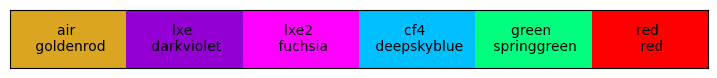

In [4]:

import pandas as pd
import matplotlib.pyplot as plt

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from scipy.ndimage import gaussian_filter1d
import time

from scipy import optimize as opt
from scipy import stats as sps
import iminuit
from iminuit import Minuit

import json

import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
from PDEModel import PNJunction as PNJ

import FittingTools.FittingFunctions as FF
from FittingTools.FittingFunctions import *

import FittingTools.PDE_fittingTools as SS

from cycler import cycler


MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option

rad2deg = 180/np.pi

In [5]:
file_path = os.path.join(VERA_DATA_PATH, "HPK_PDE_sept24.csv")

df = pd.read_csv(file_path, header=0)

# print(df)
# print(df.info())
print(df.tail())
print("--------------------------")

print(df['Overvoltage'].value_counts())
print(df['Angle'].value_counts())
# print(df['Wavelength'].unique())

data_angles = df['Angle'].unique()
data_voltages = df['Overvoltage'].unique()

print(data_voltages)

vera4V = [df[(df['Overvoltage'] == 4.0) & (df['Angle'] == 0)]["Wavelength"].values, df[(df['Overvoltage'] == 4.0) & (df['Angle'] == 0)]["PDE"].values, df[(df['Overvoltage'] == 4.0) & (df['Angle'] == 0)]["PDE_error"].values]
vera3V = [df[(df['Overvoltage'] == 3.0) & (df['Angle'] == 0)]["Wavelength"].values, df[(df['Overvoltage'] == 3.0) & (df['Angle'] == 0)]["PDE"].values, df[(df['Overvoltage'] == 3.0) & (df['Angle'] == 0)]["PDE_error"].values]
vera5V = [df[(df['Overvoltage'] == 5.0) & (df['Angle'] == 0)]["Wavelength"].values, df[(df['Overvoltage'] == 5.0) & (df['Angle'] == 0)]["PDE"].values, df[(df['Overvoltage'] == 5.0) & (df['Angle'] == 0)]["PDE_error"].values]

     Wavelength  Angle  Overvoltage          Resp       PDE  PDE_error
387     789.983      0            8  1.487610e-13  0.114928   0.004171
388     799.950      0            8  1.338970e-13  0.103445   0.004119
389     810.007      0            8  1.252880e-13  0.096794   0.003343
390     820.008      0            8  1.147380e-13  0.088643   0.003168
391     829.983      0            8  1.056960e-13  0.081658   0.002833
--------------------------
Overvoltage
1    49
2    49
3    49
4    49
5    49
6    49
7    49
8    49
Name: count, dtype: int64
Angle
0    392
Name: count, dtype: int64
[1 2 3 4 5 6 7 8]


In [6]:
hamX, hamY = ODL.Load_Ham_data()
hamYerr = np.repeat(0.02, len(hamY))

dict_static = {"quantum": True, "smoothSigma": None, "window":True}

## load in new json data
with open("fit_results.json", 'r') as file:
    json_fits = json.load(file)
    
## default global fit result
jsondefault_global = json_fits["HPK_VUV4"]["default_global"]
dict_default_global = {key: value[0] for key, value in jsondefault_global["fit_parameters"].items()}
dict_default_global["tOxide"] = jsondefault_global["input_parameters"]["tOxide"][0]
dict_default_global["FF"] = jsondefault_global["input_parameters"]["FF"]

print("default global:\n", dict_default_global)

## franta global fit result
jsonfranta_global = json_fits["HPK_VUV4"]["franta_global"]
dict_franta_global = {key: value[0] for key, value in jsonfranta_global["fit_parameters"].items()}
dict_franta_global["tOxide"] = jsonfranta_global["input_parameters"]["tOxide"][0]
dict_franta_global["FF"] = jsonfranta_global["input_parameters"]["FF"]
print("franta global:\n", dict_franta_global)

# plotting many dh curves
dhFranta = ODL.OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-150K.txt"))
dhFranta_warm = ODL.OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-293K.txt"))
dhDefault = ODL.OpticsData()

default global:
 {'dp_star': 1.02, 'Xpn': 2342, 'dw_star': 13574, 'Ve': 1.789, 'Vh': 16.62, 'tOxide': 17.2, 'FF': 0.6}
franta global:
 {'dp_star': 0.82, 'Xpn': 2675, 'dw_star': 5850, 'Ve': 1.83, 'Vh': 4.68, 'tOxide': 19.51, 'FF': 0.6}
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/Franta_data/Franta-150K.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/Franta_data/Franta-293K.txt
loaded and interpolated successfully.
-------

temperature scaling not tested/validated below 300nm, be careful


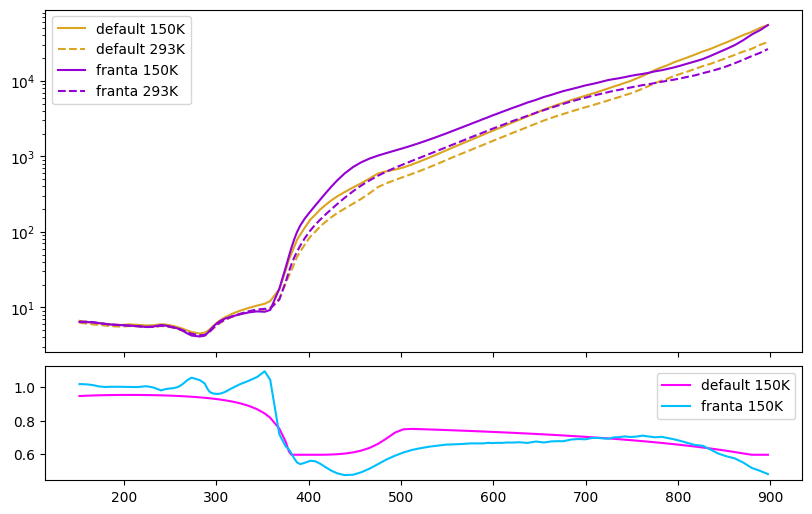

In [7]:
## comparing k values
defK = dhDefault.SiIndex(hamX).imag
defKWarm = None

photonDefault_warm = PhotonInfo(wlen = hamX, theta_1 = 0, materialTemp=None, dataHelper= dhDefault)
photonDefault = PhotonInfo(wlen = hamX, theta_1 = 0, materialTemp=150, dataHelper= dhDefault)

photonFranta = PhotonInfo(wlen = hamX, theta_1 = 0, materialTemp=None, dataHelper= dhFranta)
photonFranta_warm = PhotonInfo(wlen = hamX, theta_1 = 0, materialTemp=None, dataHelper= dhFranta_warm)


frantaK = dhFranta.SiIndex(hamX).imag
frantaKWarm = dhFranta_warm.SiIndex(hamX).imag

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5), sharex=True, height_ratios=[3, 1])
fig.tight_layout(pad=0.0)


ms.ResetColorCycle()
ax1.semilogy(hamX, 1/photonDefault.muSi, label="default 150K", color=ms.GetNextColor())
ax1.semilogy(hamX, 1/photonDefault_warm.muSi, label="default 293K", linestyle = "--", color=ms.GetNextColor(1))
ax1.semilogy(hamX, 1/photonFranta.muSi, label="franta 150K", color=ms.GetNextColor())
ax1.semilogy(hamX, 1/photonFranta_warm.muSi, label="franta 293K", linestyle = "--", color=ms.GetNextColor(1))

ax1.legend()

ax2.plot(hamX, photonDefault.muSi/photonDefault_warm.muSi, label="default 150K", color=ms.GetNextColor())
ax2.plot(hamX, photonFranta.muSi/photonFranta_warm.muSi, label="franta 150K", color=ms.GetNextColor())
ax2.legend()

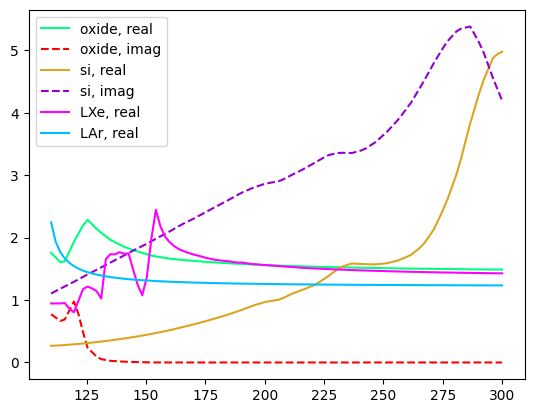

In [8]:
xUV = np.linspace(110, 300, 100)

photonDefault = PhotonInfo(wlen = xUV, theta_1 = 0, materialTemp=None, dataHelper= dhDefault)
photonLXe = PhotonInfo(wlen = xUV, theta_1 = 0, materialTemp=None, dataHelper= dhFranta, mediumStr = "LXe")
photonLAr = PhotonInfo(wlen = xUV, theta_1 = 0, materialTemp=None, dataHelper= dhFranta, mediumStr = "LAr")

plt.plot(xUV, photonDefault.nOxide.real, linestyle = "-", color=ms.GetNextColor(), label="oxide, real")
plt.plot(xUV, photonDefault.nOxide.imag, linestyle = "--", color=ms.GetNextColor(), label="oxide, imag")

plt.plot(xUV, photonDefault.nSi.real, linestyle = "-", color=ms.GetNextColor(), label="si, real")
plt.plot(xUV, photonDefault.nSi.imag, linestyle = "--", color=ms.GetNextColor(), label="si, imag")

plt.plot(xUV, photonLXe.nVacuum.real, linestyle = "-", color=ms.GetNextColor(), label="LXe, real")

plt.plot(xUV, photonLAr.nVacuum.real, linestyle = "-", color=ms.GetNextColor(), label="LAr, real")
# plt.plot(xUV, photonLXe.nVacuum.imag, linestyle = "--", color=ms.GetNextColor(), label="LXe, imag")

# plt.xlim(100, 190)
plt.legend()
plt.show()

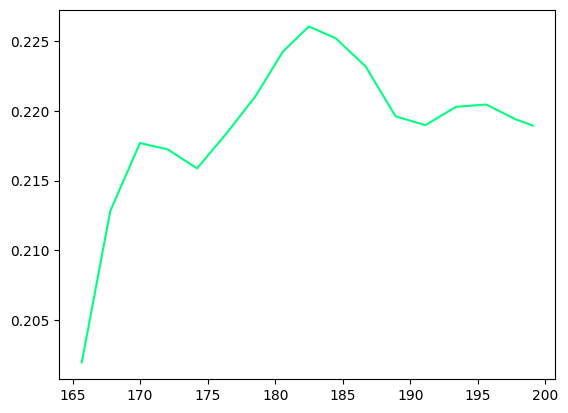

In [9]:
## import data
# triumf data is 3.5V, ihep is 4V
tri_wlen, tri_pde, ihep_wlen, ihep_pde = np.loadtxt(os.path.join(LITERATURE_DATA_PATH, "nexo_gallina_performanceNovel", "nexo_gallina_VUVPDE_4V.csv"), delimiter=",", skiprows=2, unpack=True)
ihep_wlen = ihep_wlen[:-1]
ihep_pde = ihep_pde[:-1]

plt.plot(ihep_wlen, ihep_pde, label="IHEP 4V", color=ms.GetNextColor())

this path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
temperature scaling not tested/validated below 300nm, be careful
temperature scaling not tested/validated below 300nm, be careful
temperature scaling not tested/validated below 300nm, be careful
temperature scaling not tested/validated below 300nm, be careful
temperature scaling not tested/validated below 300nm, be careful
temperature scaling not tested/validated below 300nm, be careful
PDE becomes affected by charge carrier freezeout below 150k, photo absorption alone may not be enough.
temperature scaling not tested/validated below 300nm, be careful
PDE becomes affected by charge carrier freezeout below 150k, photo absorption alone may not be enough.
temperature scaling not tested/validated below 300nm, be careful
PDE becomes affected by charge carrier freezeout below 150k, photo absorption alone may not be enough.


/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/MathEquations.py:85: RuntimeWarning: invalid value encountered in sqrt
  return np.array(n_squared**0.5)  # Return complex index n + ik, with k = 0 for Sellmeier. syke just return n
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


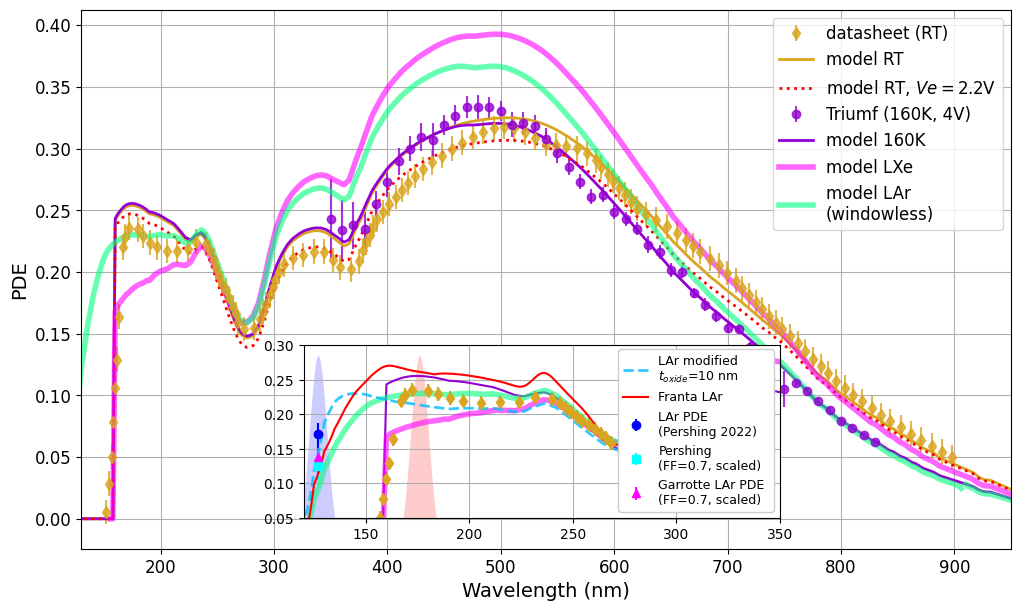

In [10]:
# ---- Definitions / Parameters / Data ---------------------------------------------------
fig, (ax1) = plt.subplots(1, sharex=True, figsize=(12, 7))

# constants
hpkVoltage = 4.3
argonX = np.arange(120, 1100, 2.0)

# literature / datapoints
pershingPDE = [0.172, 0.03, 0.016]
pershingFF07 = np.array([0.147, 0.024, 0.011]) * 0.6/0.7
garrottePDEFF07 = np.array([0.162, 0.028, 0.015]) * 0.6/0.7

# bamaPDE_angle = np.loadtxt(os.path.join(LITERATURE_DATA_PATH

print("this path:", OPTICS_DATA_PATH)

# plotting color cycle / styles
colors = plt.cm.cool(np.linspace(0, 1, 4))
plt.rc('axes', prop_cycle=cycler('color', colors))
ms.ResetColorCycle()

warmColor = ms.air.col
coldColor = ms.lxe.col
larColor = ms.green.col
lxeColor = ms.lxe2.col
frantaLine = "--"

# dicts used for model calls (copy originals so modifications below are explicit)
cd_noWindow = {**dict_static}
cd_noWindow["window"] = False

defaultDict_thinOx = {**dict_default_global}
defaultDict_thinOx["tOxide"] = 10
# defaultDict_thinOx["dp_star"] = 1.5
# defaultDict_thinOx["Ve"] = 0.5

perfectiPDE_dict = {**dict_default_global}
perfectiPDE_dict["dp_star"] = 0.001
perfectiPDE_dict["Ve"] = 0.1

# gaussian spectra used in inset
x = np.linspace(110, 200, 100)
lxeGauss = sps.norm.pdf(x, loc=176, scale=10/2.335)
lxeGauss = lxeGauss/lxeGauss.max()/3.5

larGauss = sps.norm.pdf(x, loc=127, scale=10/2.335)
larGauss = larGauss/larGauss.max()/3.5



# ---- Compute model curves (no plotting here) -----------------------------------------
# default cold
yFit_default_global_cold = FF.PDE_allArgs_wlen_parametrized_forMedium(
  wlen=argonX, dh=dhDefault, Temperature=160, medium="vacuum",
  voltage=hpkVoltage, theta1=0, **dict_default_global, **dict_static)

# default, cold, no window (vacuum)
yFit_default_global_cold_no_window = FF.PDE_allArgs_wlen_parametrized_forMedium(
  wlen=argonX, dh=dhDefault, Temperature=160, medium="vacuum",
  voltage=hpkVoltage, theta1=0, **dict_default_global, **cd_noWindow)

# franta cold
yFit_frantaGlobal_cold = FF.PDE_allArgs_wlen_parametrized_forMedium(
  wlen=argonX, dh=dhFranta, Temperature=None, medium="vacuum",
  voltage=hpkVoltage, theta1=0, **dict_franta_global, **dict_static)

# default warm
yFit_default_global_warm = FF.PDE_allArgs_wlen_parametrized_forMedium(
  wlen=argonX, dh=dhDefault, Temperature=273, medium="vacuum",
  voltage=hpkVoltage, theta1=0, **dict_default_global, **dict_static)

# default warm, Ve = 2.2
yFit_default_global_warm_Pe = FF.PDE_allArgs_wlen_parametrized_forMedium(
  wlen=argonX, dh=dhDefault, Temperature=273, medium="vacuum",
  voltage=hpkVoltage, theta1=0, **{**dict_default_global, "Ve": 2.2}, **dict_static)

# LXe / LAr curves
yFit_global_xenon = FF.PDE_allArgs_wlen_parametrized_forMedium(
  wlen=argonX, dh=dhDefault, Temperature=160, medium="lxe",
  voltage=hpkVoltage, theta1=0, **dict_default_global, **dict_static)

yFit_global_argon = FF.PDE_allArgs_wlen_parametrized_forMedium(
  wlen=argonX, dh=dhDefault, Temperature=90, medium="lar",
  voltage=hpkVoltage, theta1=0, **dict_default_global, **cd_noWindow)

# closer-range argon (for inset)
closerX = np.arange(110, 300, 0.5)
yFit_global_argon_closer = FF.PDE_allArgs_wlen_parametrized_forMedium(
  wlen=closerX, dh=dhDefault, Temperature=90, medium="lar",
  voltage=hpkVoltage, theta1=0, **dict_default_global, **cd_noWindow)

argonFranta = FF.PDE_allArgs_wlen_parametrized_forMedium(
  wlen=closerX, dh=dhFranta, Temperature=None, medium="lar",
  voltage=hpkVoltage, theta1=0, **dict_franta_global, **cd_noWindow)

# modified argon with thinner oxide
yFit_gAr_better = FF.PDE_allArgs_wlen_parametrized_forMedium(
  wlen=closerX, dh=dhDefault, Temperature=90, medium="lar",
  voltage=hpkVoltage, theta1=0, **defaultDict_thinOx, **cd_noWindow)


# ---- Plotting (grouped) --------------------------------------------------------------
# datapoints / experimental markers
dW = ax1.errorbar(hamX, hamY, hamYerr/2, alpha=0.8,
          label="Datasheet (RT)", linestyle="None", marker="d", color=warmColor)

dC = ax1.errorbar(vera4V[0], vera4V[1], vera4V[2], alpha=0.8,
          label="TRIUMF (4V, 160K)", linestyle="None", marker="o", color=coldColor)

# model lines on main axes
mWD = ax1.plot(argonX, yFit_default_global_warm, label="model, RT",
         linestyle="-", linewidth=2, color=warmColor)

mCD = ax1.plot(argonX, yFit_default_global_cold, label="model, 160K",
         linestyle="-", linewidth=2, alpha=1.0, color=coldColor)

mWD_Pe = ax1.plot(argonX, yFit_default_global_warm_Pe, label="model, RT, Ve=2.2",
         linestyle=":", linewidth=2, color=ms.red.col)

# mCF = ax1.plot(argonX, yFit_frantaGlobal_cold, label="model (Franta), cold",
#          linestyle=frantaLine, linewidth=2, alpha=1.0, color=coldColor)


# (franta warm computed but not shown by default)
# ax1.plot(argonX, yFit_frantaGlobal_warm, label="Franta warm", linestyle=frantaLine, linewidth=2, color=warmColor)

xeMask = argonX > 155
xenonStyle = {"linestyle": "-", "linewidth": 4, "alpha": 0.6, "color": lxeColor}
mXe = ax1.plot(argonX[xeMask], yFit_global_xenon[xeMask], label="model LXe, 160 K", **xenonStyle)

argonStyle = {"linestyle": "-", "linewidth": 4, "alpha": 0.6, "color": larColor}
mAr = ax1.plot(argonX, yFit_global_argon, label="model LAr, 90 K\n(no window)", **argonStyle)

# inset axes and its contents
spot = (320, -0.005, 420, 0.14)  # (x0, y0, width, height) in axes coordinates
axins = inset_axes(ax1, width="100%", height="100%", loc="lower left",
           bbox_to_anchor=spot, bbox_transform=ax1.transData)

# inset: datapoints + selected models
axins.errorbar(hamX, hamY, hamYerr/2, alpha=1.0, linestyle="None", marker="d", color=warmColor)
axins.errorbar(127, pershingPDE[0], yerr=np.array([[pershingPDE[1]],[pershingPDE[2]]]), fmt='o', color='blue', label="LAr PDE\n(Pershing 2022)", markersize=6)

axins.errorbar(127, pershingFF07[0], yerr=np.array([[pershingFF07[1]],[pershingFF07[2]]]), fmt='s', color='cyan', label="Pershing\n(FF=0.7, scaled)", markersize=6)
axins.errorbar(127, garrottePDEFF07[0], yerr=np.array([[garrottePDEFF07[1]],[garrottePDEFF07[2]]]), fmt='^', color='magenta', label="Garrotte LAr PDE \n(FF=0.7, scaled)", markersize=6)

axins.plot(argonX, yFit_default_global_cold, color=ms.lxe.col)
# axins.plot(argonX, yFit_default_global_warm, color=ms.air.col)
axins.plot(argonX[xeMask], yFit_global_xenon[xeMask], **xenonStyle)
axins.plot(closerX, yFit_global_argon_closer, **argonStyle)

## plotting gallina nexo data
# axins.errorbar(tri_wlen, tri_pde, 0.01, linestyle="None", marker="x", label="IHEP 4V", markersize=6)

## hypothetical improvements
argonStyle_2 = {**argonStyle, "linestyle": "--"}
argonStyle_2["alpha"] = 0.8
argonStyle_2["linewidth"] = 2
argonStyle_2["color"] = ms.cf4.col
# axins.plot(argonX, yFit_default_global_cold_no_window, label="model, cold, no window", linestyle=":", linewidth=2, alpha=1.0, color=coldColor)
axins.plot(closerX, yFit_gAr_better, label=f"LAr modified\n$t_{{oxide}}$={defaultDict_thinOx['tOxide']} nm", **argonStyle_2)

# optional Franta LAr (commented)
axins.plot(closerX, argonFranta, label="Franta LAr", linestyle="-", color=ms.red.col)

# inset: spectra / modified-oxide argon
axins.fill_between(x, lxeGauss, alpha=0.2, color='red', linewidth=0)
axins.fill_between(x, larGauss, alpha=0.2, linewidth=0, color='blue')

# inset cosmetics
axins.legend(loc="lower right", fontsize=9, framealpha = 1.0)
axins.tick_params(axis='y', labelsize=10)
axins.tick_params(axis='x', labelsize=10)
axins.set_xlim(120, 350)
axins.set_ylim(0.05, 0.3)
axins.grid()

# main axes cosmetics / legend
ax1.set_xlim(130, 950)
# Build a manual legend with requested ordering
legend_handles = [dW, mWD[0], mWD_Pe[0], dC, mCD[0], mXe[0], mAr[0]]
legend_labels = [
    "datasheet (RT)",
    "model RT",
    r"model RT, $Ve=2.2$V",
    "Triumf (160K, 4V)",
    "model 160K",
    "model LXe",
    "model LAr\n(windowless)"
]
ax1.legend(legend_handles, legend_labels, fontsize=12, loc="upper right")

ax1.set_xlabel("Wavelength (nm)", fontsize=14)
ax1.set_ylabel("PDE", fontsize=14)
ax1.tick_params(axis='x', labelsize=12)
ax1.tick_params(axis='y', labelsize=12)
ax1.grid()

temperature scaling not tested/validated below 300nm, be careful
PDE becomes affected by charge carrier freezeout below 150k, photo absorption alone may not be enough.
n for LAr [1.42772789]
LAr total transmission at 128 nm: 0.1701
-------
Pershing PDE: 0.1720
Pershing PDE/FF: 0.2867    = T x iPDE

temperature scaling not tested/validated below 300nm, be careful
PDE becomes affected by charge carrier freezeout below 150k, photo absorption alone may not be enough.
parameters: {'dp_star': 1.02, 'Xpn': 2342, 'dw_star': 13574, 'Ve': 1.789, 'Vh': 16.62, 'tOxide': 17.2, 'FF': 0.6} {'quantum': True, 'smoothSigma': None, 'window': False}
-----
Sum of LAr PDE with Gaussian weighting: 0.0903
temperature scaling not tested/validated below 300nm, be careful
PDE becomes affected by charge carrier freezeout below 150k, photo absorption alone may not be enough.
17.2
LAr weighted total transmission at 127 nm: 0.1741 for t_oxide=17.20 nm


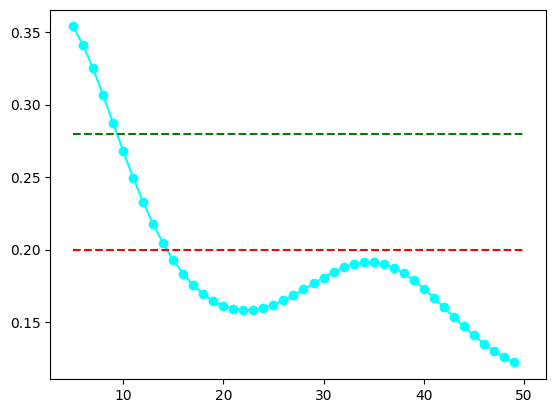

In [11]:
dictToCalc = dict_default_global # defaultDict_thinOx, dict_franta_global
dhToCalc = dhDefault
# dictToCalc = perfectiPDE_dict # if you want perfect iPDE

## franta
# dictToCalc = dict_franta_global
# dhToCalc = dhFranta

perfectiPDE_dict["tOxide"] = dictToCalc["tOxide"] # have to do this

wlenCenter = 127

temp = 90 if dhToCalc == dhDefault else None
## done selecting inputs

photonLar = PhotonInfo(wlen = np.array([wlenCenter]), theta_1 = 0, materialTemp=temp, dataHelper= dhToCalc, mediumStr = "LAr")
# photonLar.nOxide = photonLar.nOxide.real + 1j*0.0  # set imaginary part to zero for this calc
# photonLar.nVacuum = 1.5 # increase n of LAr
print("n for LAr", photonLar.nVacuum)

# larT = photonLar.Wave_TotalTransmission(dictToCalc["tOxide"])[0].real
larT = photonLar.Wave_TotalTransmission(19.4)[0].real
print(f"LAr total transmission at 128 nm: {larT:.4f}")

# print(f"T x FF = {larT * 0.6:.2f}")

# noK_dh = ODL.OpticsData()
# noK_dh = dhFranta
# noK_dh.Si

noFFPDE = pershingPDE[0] / 0.6
print(f"-------\nPershing PDE: {pershingPDE[0]:.4f}")
print(f"Pershing PDE/FF: {noFFPDE:.4f}    = T x iPDE\n")
# print(f"Pershing iPDE: {(noFFPDE/larT):.4f} \n\n")


### convolving PDE with Gaussian spectrum ###
xAr_convolve = np.arange(115, 140, 0.2)
argonConvolve = FF.PDE_allArgs_wlen_parametrized_forMedium(
  wlen=xAr_convolve, dh=dhToCalc, Temperature=temp, medium="lar",
  voltage=hpkVoltage, theta1=0, **dictToCalc, **cd_noWindow) # default
print("parameters:", dictToCalc, cd_noWindow)

larGauss_convolve = sps.norm.pdf(xAr_convolve, loc=wlenCenter, scale=10/2.335)
normalized_argon_gauss = larGauss_convolve / np.sum(larGauss_convolve)

argon_weighted = np.sum(argonConvolve.real * normalized_argon_gauss)
print(f"-----\nSum of LAr PDE with Gaussian weighting: {argon_weighted:.4f}")

### Convolving transmission separately ###
photonLar = PhotonInfo(wlen = xAr_convolve, theta_1 = 0, materialTemp=temp, dataHelper= dhToCalc, mediumStr = "LAr")
# photonLar.nOxide = photonLar.nOxide.real + 0*1j*photonLar.nOxide.imag   # set imaginary part to zero for this calc
# photonLar.nVacuum *= 1.1

toxHere = dictToCalc["tOxide"]
print(dictToCalc["tOxide"])
toxHere = 17.2
argonT_weighted = np.sum(photonLar.Wave_TotalTransmission(toxHere).real * normalized_argon_gauss)
print(f"LAr weighted total transmission at 127 nm: {argonT_weighted:.4f} for t_oxide={toxHere:.2f} nm")

toxVals = np.arange(5, 50, 1)
tfullVals = np.array([np.sum(photonLar.Wave_TotalTransmission(tox).real * normalized_argon_gauss) for tox in toxVals])
plt.plot(toxVals, tfullVals, marker='o')

plt.hlines(0.2, xmin=5, xmax=50, colors='r', linestyles='--', label='single-wlen T value')
plt.hlines(0.28, xmin=5, xmax=50, colors='g', linestyles='--', label='Pershing PDE/FF')
plt.show()

Text(0.5, 1.0, 'Total transmission vs angle for t_oxide=17.20 nm')

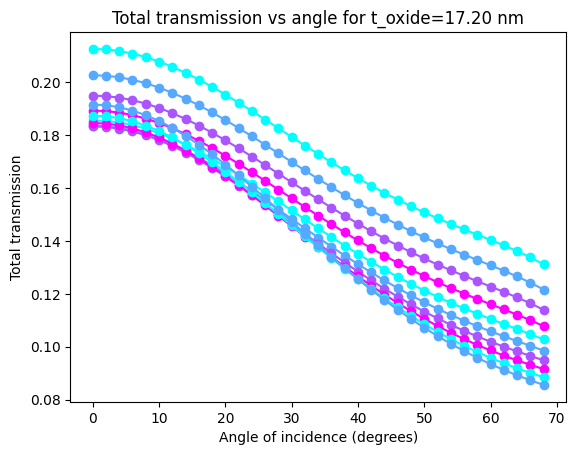

In [14]:
toxes = np.arange(15, 25, 1)
angles = np.arange(0, 70, 2)
photonLar = PhotonInfo(wlen = 128, theta_1 = angles, materialTemp=None, dataHelper= dhToCalc, mediumStr = "LAr")
for tox in toxes:
    trans = photonLar.Wave_TotalTransmission(tox).real
    plt.plot(angles, trans, marker='o')

plt.xlabel("Angle of incidence (degrees)")
plt.ylabel("Total transmission")
plt.title(f"Total transmission vs angle for t_oxide={toxHere:.2f} nm")


---
### Compare to Pershing result

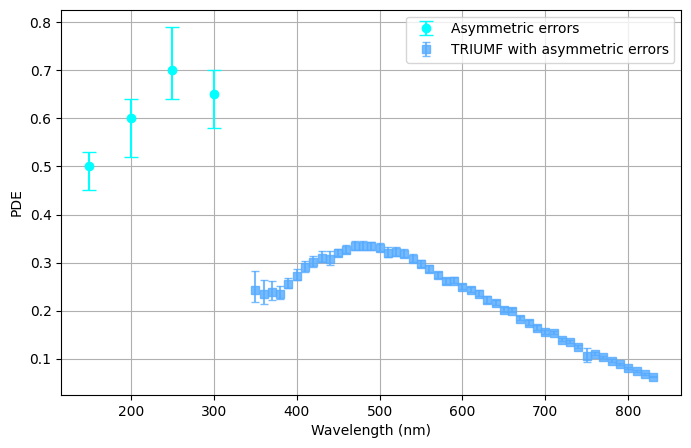

In [ ]:
# Example: Creating asymmetric error bars for your data

# Method 1: If you have separate upper and lower error arrays
x_data = np.array([150, 200, 250, 300])
y_data = np.array([0.5, 0.6, 0.7, 0.65])
lower_errors = np.array([0.05, 0.08, 0.06, 0.07])  # always positive
upper_errors = np.array([0.03, 0.04, 0.09, 0.05])  # always positive

# Plot with asymmetric errors
plt.figure(figsize=(8, 5))
plt.errorbar(x_data, y_data, yerr=[lower_errors, upper_errors], 
             fmt='o', capsize=5, label='Asymmetric errors')

# Method 2: If your errors are stored as [value, -lower, +upper] like pershingPDE
# For each point, you'd do:
# plt.errorbar(x, central_value, yerr=[abs(lower_error), upper_error], ...)

# Method 3: Converting your current symmetric errors to asymmetric
# If you want to make your TRIUMF data have asymmetric errors:
vera4V_lower = vera4V[2] * 0.8  # 20% smaller lower errors
vera4V_upper = vera4V[2] * 1.2  # 20% larger upper errors

plt.errorbar(vera4V[0], vera4V[1], yerr=[vera4V_lower, vera4V_upper],
             fmt='s', alpha=0.8, label="TRIUMF with asymmetric errors",
             capsize=3)

plt.xlabel("Wavelength (nm)")
plt.ylabel("PDE")
plt.legend()
plt.grid(True)
plt.show()